In [2]:
# You can double-check your Python path like this...
import sys
sys.path.insert(0, "..")
print(sys.path)

['..', '/Users/hezheng/Desktop/engineering/3rd year/B1/Pratice 1/b1-coding-practical-mt24/notebooks', '/opt/anaconda3/lib/python312.zip', '/opt/anaconda3/lib/python3.12', '/opt/anaconda3/lib/python3.12/lib-dynload', '', '/opt/anaconda3/lib/python3.12/site-packages', '/opt/anaconda3/lib/python3.12/site-packages/aeosa']


# Simulate closed-loop


### Closed-loop Simulation with PD Control

This demonstration integrates the PD controller with the submarine dynamics model to simulate a closed-loop depth control system.

- **Controller:** A PD controller with proportional gain \(K_P = 0.15\) and derivative gain \(K_D = 0.6\).
- **Mission:** The reference depth profile is loaded from `data/mission.csv`.
- **Simulation:** The closed-loop system is simulated with random disturbances to evaluate the controller's performance.
- **Visualisation:** The resulting trajectory is plotted against the reference depth to assess tracking accuracy and observe deviations such as overshoot and tracking error.

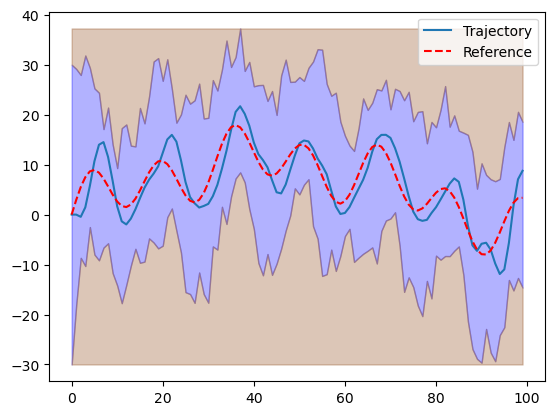

In [3]:
# Import relevant modules
from uuv_mission.dynamic import Submarine, ClosedLoop, Mission
from uuv_mission.control import PDController

sub = Submarine()
controller = PDController(kp=0.15, kd=0.6)
closed_loop = ClosedLoop(sub, controller)
mission = Mission.from_csv("../data/mission.csv")

trajectory = closed_loop.simulate_with_random_disturbances(mission)
trajectory.plot_completed_mission(mission)